### Exploração inicial

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/WineQT.csv')
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


In [6]:
print(f"Null values:\n{df.isnull().sum()},\n\nDuplicates: {df.drop(columns='Id').duplicated().sum()}")

Null values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64,

Duplicates: 125


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1143.0,8.311111,1.747595,4.60000,7.10000,7.90000,9.100000,15.90000
volatile acidity,1143.0,0.531339,0.179633,0.12000,0.39250,0.52000,0.640000,1.58000
citric acid,1143.0,0.268364,0.196686,0.00000,0.09000,0.25000,0.420000,1.00000
residual sugar,1143.0,2.532152,1.355917,0.90000,1.90000,2.20000,2.600000,15.50000
chlorides,1143.0,0.086933,0.047267,0.01200,0.07000,0.07900,0.090000,0.61100
free sulfur dioxide,1143.0,15.615486,10.250486,1.00000,7.00000,13.00000,21.000000,68.00000
total sulfur dioxide,1143.0,45.914698,32.782130,6.00000,21.00000,37.00000,61.000000,289.00000
density,1143.0,0.996730,0.001925,0.99007,0.99557,0.99668,0.997845,1.00369
pH,1143.0,3.311015,0.156664,2.74000,3.20500,3.31000,3.400000,4.01000
sulphates,1143.0,0.657708,0.170399,0.33000,0.55000,0.62000,0.730000,2.00000


## 1. Compreensão do problema

In [8]:
df['alta_qualidade'] = (df['quality'] >= 7).astype(int)

print(df['alta_qualidade'].value_counts())
print()
print(df['alta_qualidade'].value_counts(normalize=True).round(3)*100)

alta_qualidade
0    984
1    159
Name: count, dtype: int64

alta_qualidade
0    86.1
1    13.9
Name: proportion, dtype: float64


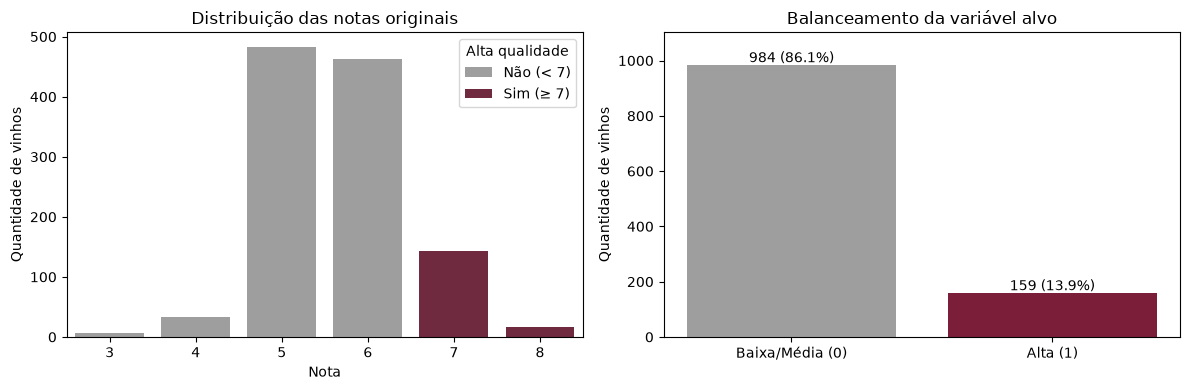

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.countplot(data=df, x='quality', hue='alta_qualidade', palette=['#9e9e9e', '#7b1e3a'], ax=axes[0])
axes[0].set_title('Distribuição das notas originais')
axes[0].set_xlabel('Nota')
axes[0].set_ylabel('Quantidade de vinhos')
axes[0].legend(title='Alta qualidade', labels=['Não (< 7)', 'Sim (≥ 7)'])

contagem = df['alta_qualidade'].value_counts().sort_index()
axes[1].bar(['Baixa/Média (0)', 'Alta (1)'], contagem.values, color=['#9e9e9e', '#7b1e3a'])
for i, v in enumerate(contagem.values):
    axes[1].text(i, v + 10, f'{v} ({v / contagem.sum():.1%})', ha='center')
axes[1].set_ylim(0, contagem.max() * 1.12)
axes[1].set_title('Balanceamento da variável alvo')
axes[1].set_ylabel('Quantidade de vinhos')

plt.tight_layout()
plt.show()

### Histogramas

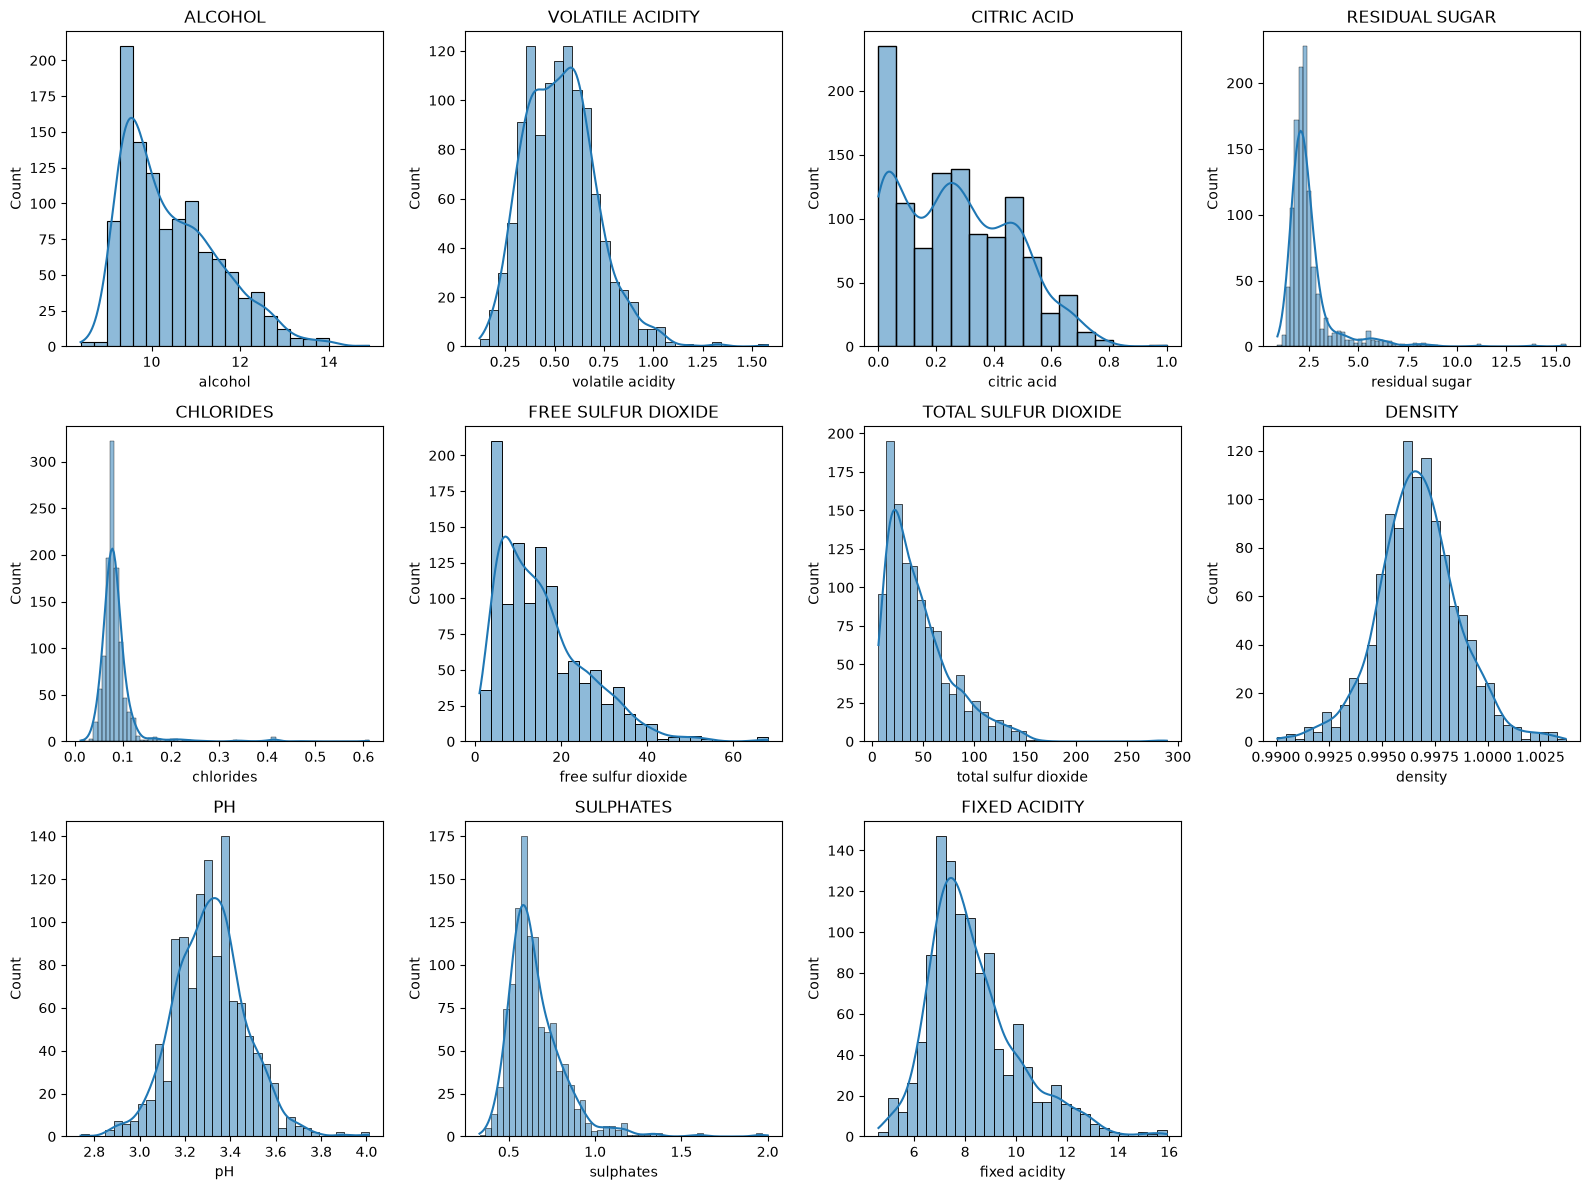

In [10]:
colunas = ['alcohol', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides',
           'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'fixed acidity']

fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(colunas):
    sns.histplot(data=df, x =col, kde=True, ax=axes[i])
    axes[i].set_title(f'{str.upper(col)}')

fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

In [11]:
assimetria = df[colunas].skew().to_frame(name='skew')

def classificar(valor):
    if abs(valor) >= 1:
        return 'Forte'
    elif abs(valor) >= 0.5:
        return 'Moderada'
    else:
        return 'Sem assimetria'

assimetria['Assimetria'] = assimetria['skew'].apply(classificar)

In [12]:
assimetria.sort_values(by='skew', ascending=False).round(3)

,skew,Assimetria
chlorides,6.026,Forte
residual sugar,4.361,Forte
sulphates,2.497,Forte
total sulfur dioxide,1.666,Forte
free sulfur dioxide,1.231,Forte
fixed acidity,1.045,Forte
alcohol,0.863,Moderada
volatile acidity,0.682,Moderada
citric acid,0.372,Sem assimetria
pH,0.221,Sem assimetria


**CONCLUSÃO ASSIMETRIA:**

Cauda longa para a direita em 6 atributos: "Chlorides", "Residual Sugar", "Sulphates", "Total sulfur dioxide", "Free sulfur dioxide" e "Fixed Acidity".

Chlorides e Residual Sugar principalmente sugerem muitos outliers.

Citric Acid não tem assimetria, e além disso a maioria está perto de zero, parece que não tem em muitos vinhos

### Boxplots

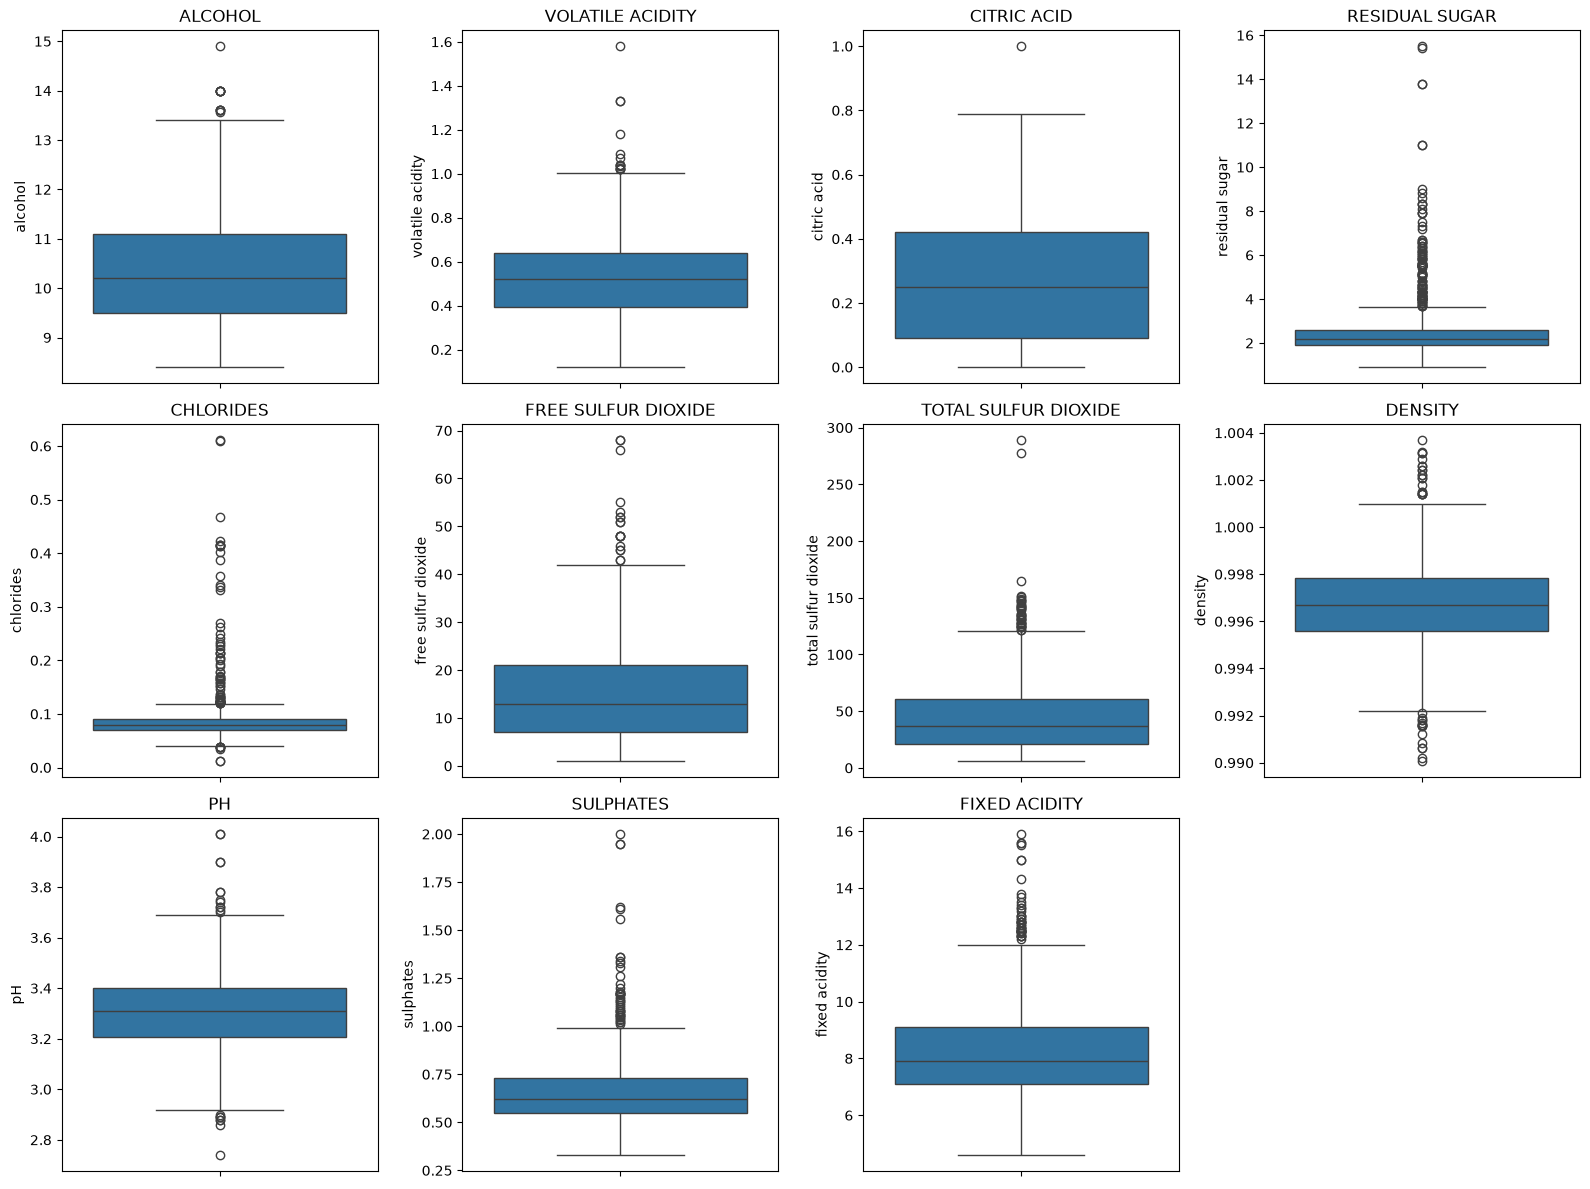

In [13]:
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(colunas):
    sns.boxplot(data=df, y =col, ax=axes[i])
    axes[i].set_title(f'{str.upper(col)}')

fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

**CONCLUSÃO OUTLIERS:**

Como previsto, Chlorides e Residual Sugar possuem muitos outliers, vale investigar porque isso parece uma característica comum dos vinhos, serem bem diferentes nesses 2 pontos.

Citric Acid e Alcohol quase não possuem outliers, agora, Sulphates, Fixed Acidity e Total Sulfur Dioxide têm bastante.

Density e PH também têm muitos outliers apesar de não terem sido classificados com assimetria, justamente porque os outliers são para cima e para baixo, equilibrando o dado.

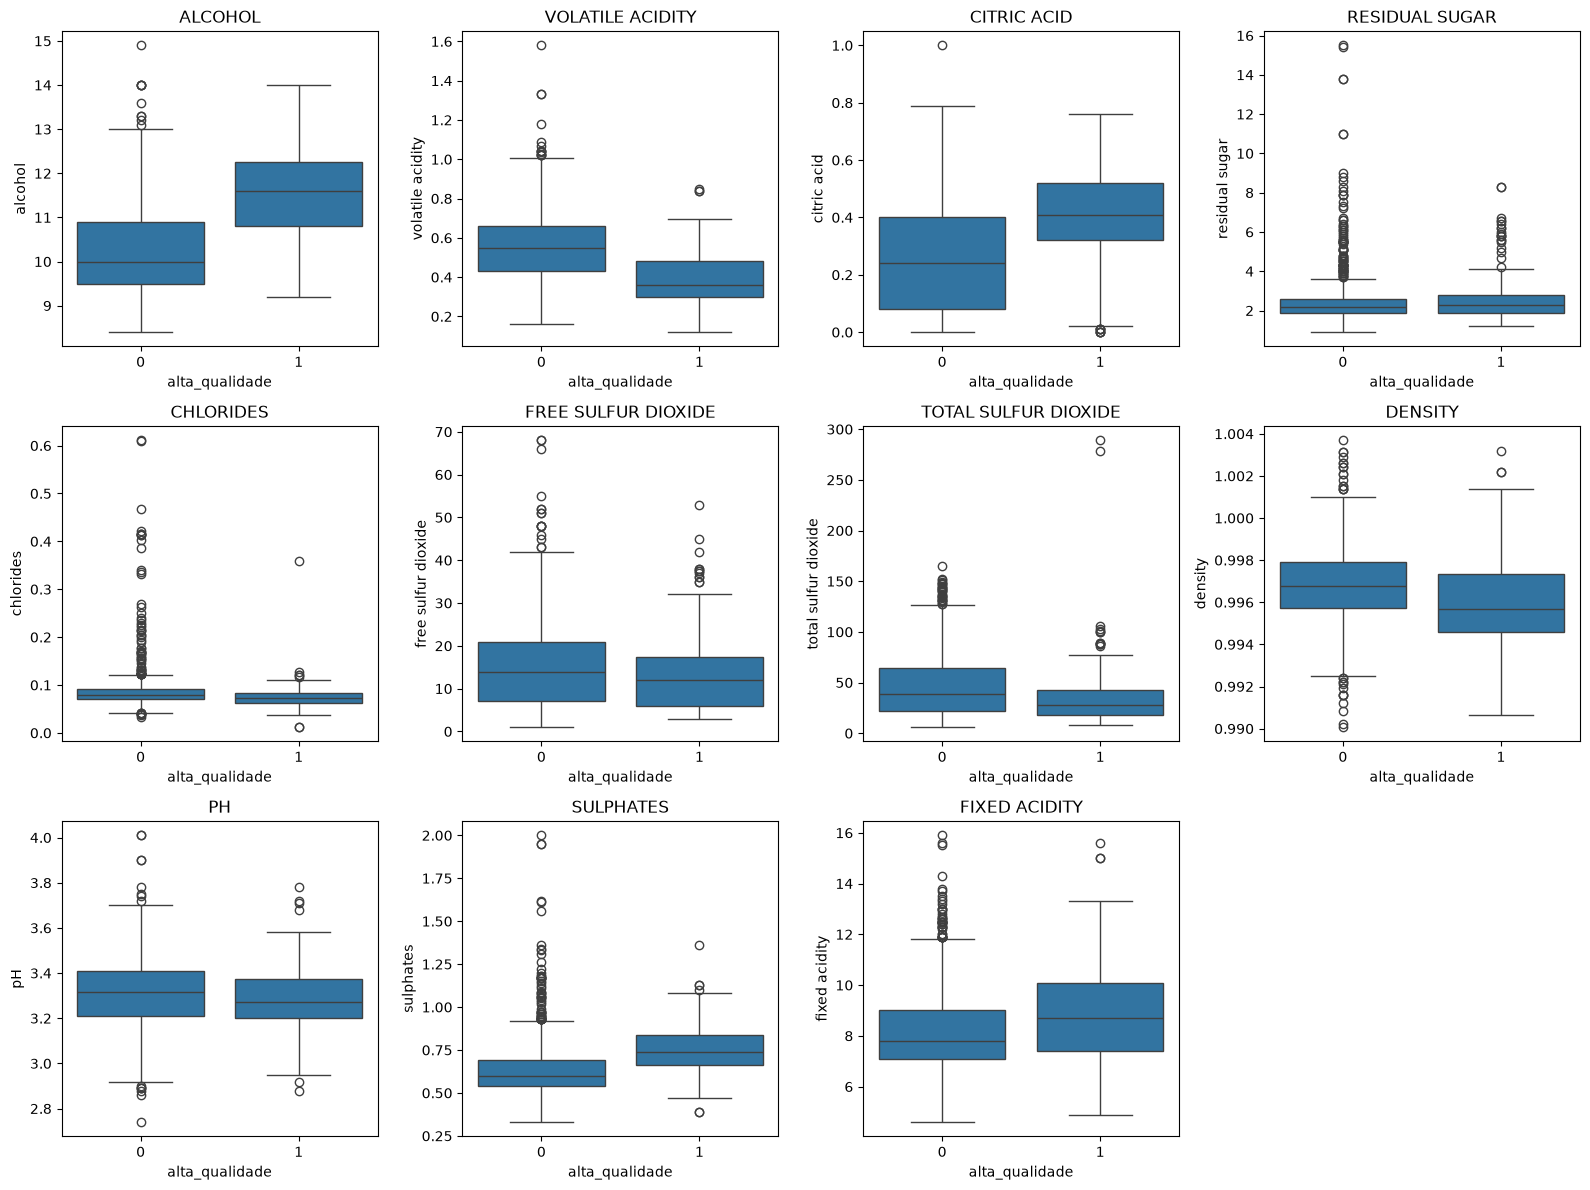

In [14]:
fig, axes = plt.subplots(nrows=3, ncols=4, figsize=(16, 12))
axes = axes.flatten()

for i, col in enumerate(colunas):
    sns.boxplot(data=df, x='alta_qualidade',y =col, ax=axes[i])
    axes[i].set_title(f'{str.upper(col)}')

fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

Os vinhos bons no geral possuem mais alcool (ALCOHOL), tem uma volatilidade de acidez (VOLATILE ACIDITY) mais baixa, são em média mais cítricos (CITRIC ACID) e com mais sulfato (SULPHATES).

O restante dos atributos parece semelhante, um atributo que tem dados semelhantes entre vinhos bons e medianos, que não era óbvio, é o açucar residual (RESIDUAL SUGAR)

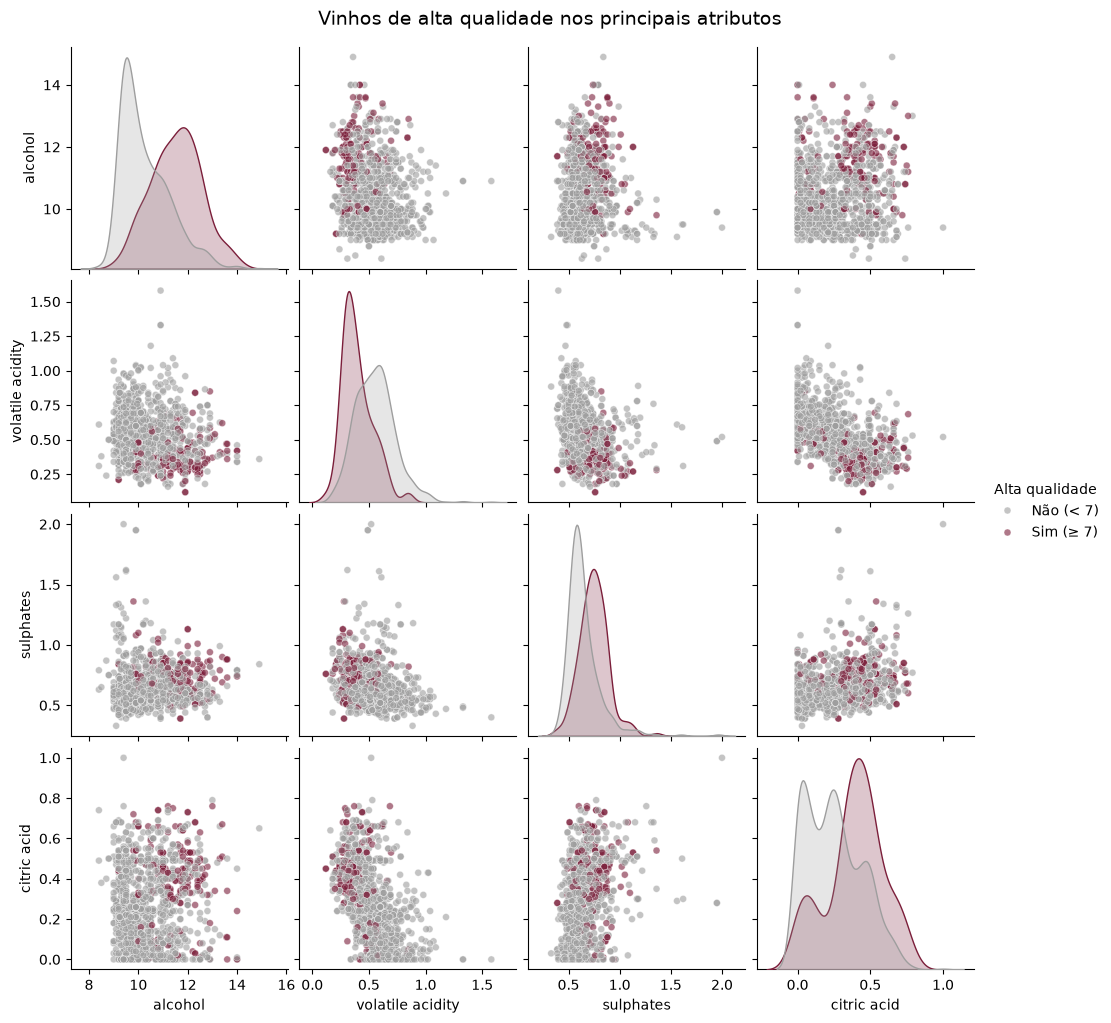

In [15]:
principais = ['alcohol', 'volatile acidity', 'sulphates', 'citric acid']

# common_norm=False: cada curva da diagonal tem a mesma área, para comparar o formato das classes
g = sns.pairplot(df, vars=principais, hue='alta_qualidade', palette=['#9e9e9e', '#7b1e3a'],
                 plot_kws={'alpha': 0.6, 's': 25}, diag_kws={'common_norm': False})

g._legend.set_title('Alta qualidade')
for texto, rotulo in zip(g._legend.texts, ['Não (< 7)', 'Sim (≥ 7)']):
    texto.set_text(rotulo)

g.figure.suptitle('Vinhos de alta qualidade nos principais atributos', y=1.02, fontsize=14)
plt.show()

**CONCLUSÃO PAIRPLOT:**

Nas curvas da diagonal, os vinhos de alta qualidade aparecem deslocados em relação aos demais nos quatro atributos principais:

| Atributo (mediana) | Alta qualidade | Demais vinhos |
|---|---|---|
| Alcohol | 11,6 | 10,0 |
| Volatile acidity | 0,36 | 0,55 |
| Sulphates | 0,74 | 0,60 |
| Citric acid | 0,41 | 0,24 |

Nos gráficos de dispersão, a separação fica mais clara quando dois atributos são vistos juntos. No cruzamento de alcohol com volatile acidity, os vinhos bons se concentram na região de **mais álcool e menos acidez volátil**: entre os 206 vinhos com álcool ≥ 11 e acidez volátil < 0,5, 46,1% são de alta qualidade, contra 13,9% na base inteira e 33,7% considerando só o álcool ≥ 11. Esses limites foram escolhidos apenas para descrever o gráfico, e não são uma regra de classificação.

Mesmo assim, as duas classes continuam bastante sobrepostas: nenhum par de atributos separa bem os vinhos bons dos demais. Isso reforça a necessidade de um modelo que combine várias variáveis.

### Perfil dos vinhos: doçura e cor

**Doçura.** A classificação de um vinho pelo açúcar residual não é universal: cada país (ou bloco) define a sua. Os dados vêm de vinhos verdes portugueses, então a regra do país de origem é a da **União Europeia**. Para comparar, aplicamos também a regra **brasileira**.

**Brasil** (Lei nº 7.678/1988 e Decreto nº 8.198/2014) — considera só o açúcar:

| Classe | Açúcar residual |
|---|---|
| Seco | até 4 g/L |
| Meio-seco | acima de 4 g/L até 25 g/L |
| Suave | acima de 25 g/L |

**União Europeia** (Regulamento Delegado (UE) 2019/33, Anexo III, Parte B) — considera o açúcar **e a acidez**, porque um vinho mais ácido parece menos doce:

| Classe | Açúcar residual | Exceção pela acidez total |
|---|---|---|
| Seco | até 4 g/L | até 9 g/L, se o açúcar não passar a acidez total em mais de 2 g/L |
| Meio seco | até 12 g/L | até 18 g/L, se o açúcar não passar a acidez total em mais de 10 g/L |
| Meio doce | até 45 g/L | — |
| Doce | acima de 45 g/L | — |

**Qual é mais tolerante ao açúcar?** Depende da faixa. Para um vinho ser chamado de **seco**, a Europa é mais tolerante (aceita até 9 g/L em vinhos ácidos, contra 4 g/L no Brasil). Já nas faixas mais doces, o **Brasil** é mais tolerante (o meio-seco vai até 25 g/L, contra 12 ou 18 g/L na Europa).

A regra europeia usa a acidez total expressa em ácido tartárico. A base traz a acidez fixa (já em ácido tartárico) e a volátil (em ácido acético), então estimamos a acidez total como `fixed acidity + 1,25 × volatile acidity`, convertendo a volátil para tartárico — é uma aproximação.

Em `residual sugar`, a unidade g/dm³ é o mesmo que g/L. As classificações são usadas apenas para descrever os vinhos e não entram no modelo.

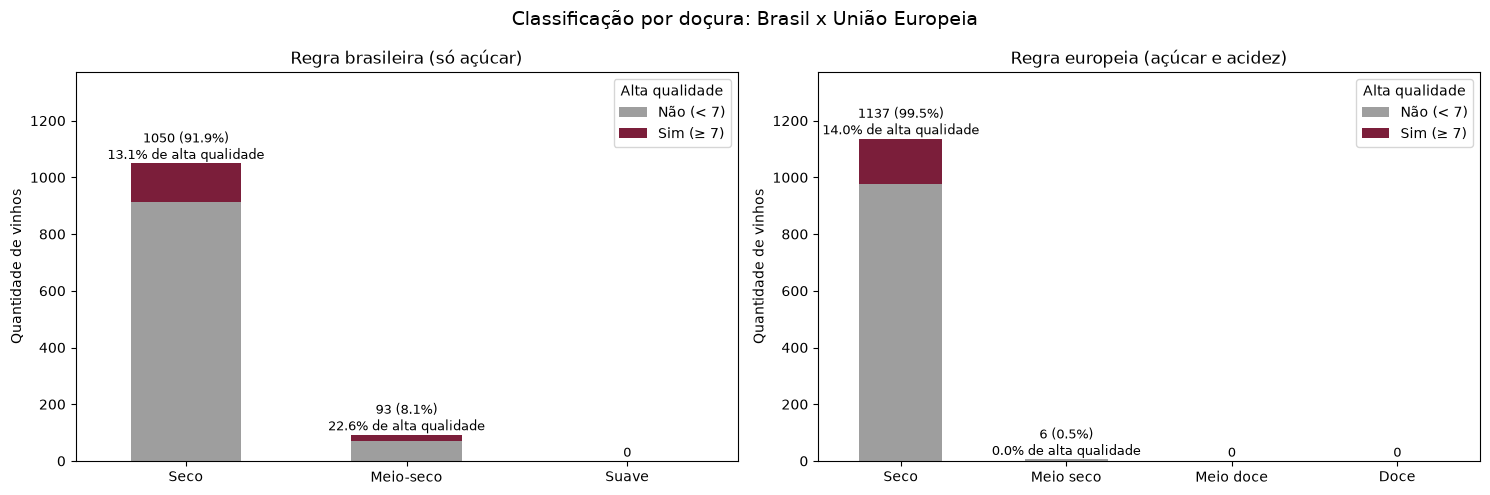

In [16]:
acucar = df['residual sugar']
acidez_total = df['fixed acidity'] + 1.25 * df['volatile acidity']  # aproximação em ácido tartárico

# Brasil: só o açúcar
classes_br = ['Seco', 'Meio-seco', 'Suave']
docura_br = pd.cut(acucar, bins=[0, 4, 25, float('inf')], labels=classes_br)

# União Europeia: açúcar e acidez
classes_ue = ['Seco', 'Meio seco', 'Meio doce', 'Doce']

def classificar_ue(acucar, acidez):
    if acucar <= 4 or (acucar <= 9 and acucar - acidez <= 2):
        return 'Seco'
    elif acucar <= 12 or (acucar <= 18 and acucar - acidez <= 10):
        return 'Meio seco'
    elif acucar <= 45:
        return 'Meio doce'
    else:
        return 'Doce'

docura_ue = pd.Series([classificar_ue(a, b) for a, b in zip(acucar, acidez_total)], index=df.index)

# As classificações ficam fora do df para não entrarem no X do modelo


def grafico_docura(ax, classificacao, classes, titulo):
    tabela = pd.crosstab(classificacao, df['alta_qualidade']).reindex(classes, fill_value=0)
    tabela.plot(kind='bar', stacked=True, color=['#9e9e9e', '#7b1e3a'], rot=0, ax=ax)
    for i, classe in enumerate(classes):
        total = tabela.loc[classe].sum()
        if total:
            texto = f'{total} ({total / len(df):.1%})\n{tabela.loc[classe, 1] / total:.1%} de alta qualidade'
        else:
            texto = '0'
        ax.text(i, total + 15, texto, ha='center', fontsize=9)
    ax.set_ylim(0, len(df) * 1.2)
    ax.set_title(titulo)
    ax.set_xlabel('')
    ax.set_ylabel('Quantidade de vinhos')
    ax.legend(title='Alta qualidade', labels=['Não (< 7)', 'Sim (≥ 7)'])


fig, axes = plt.subplots(1, 2, figsize=(15, 5))
grafico_docura(axes[0], docura_br, classes_br, 'Regra brasileira (só açúcar)')
grafico_docura(axes[1], docura_ue, classes_ue, 'Regra europeia (açúcar e acidez)')
fig.suptitle('Classificação por doçura: Brasil x União Europeia', fontsize=14)
plt.tight_layout()
plt.show()

In [17]:
pd.crosstab(docura_br.rename('Brasil'), docura_ue.rename('União Europeia'), margins=True, margins_name='Total')

União Europeia,Meio seco,Seco,Total
Brasil,,,
Seco,0,1050,1050
Meio-seco,6,87,93
Total,6,1137,1143


O cruzamento acima mostra como cada vinho foi classificado pelas duas regras. O gráfico de dispersão abaixo mostra **por que** elas divergem: no Brasil, o limite do seco é uma linha fixa em 4 g/L; na UE, o limite sobe junto com a acidez (até 9 g/L).

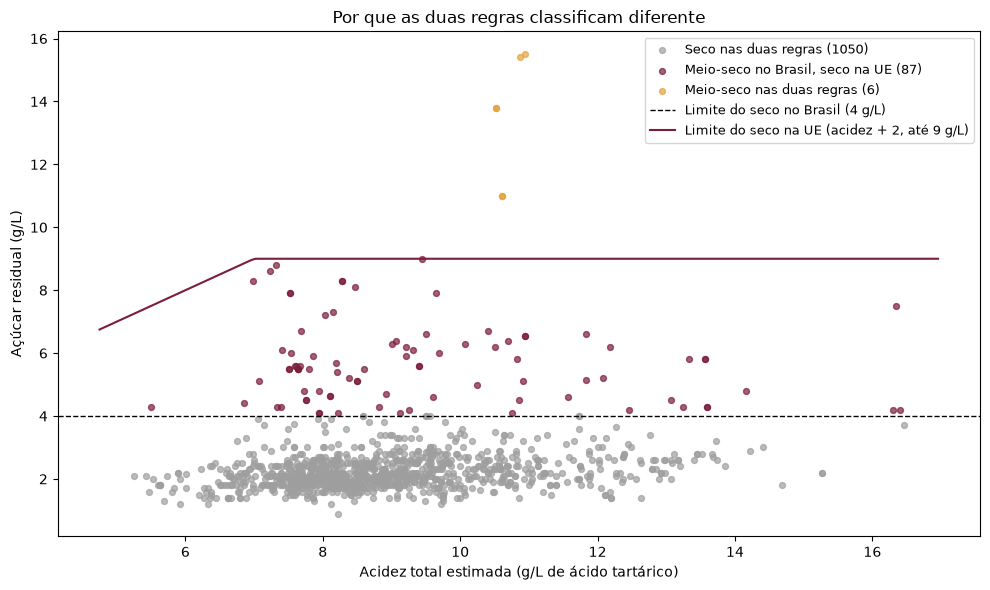

In [18]:
import numpy as np

mudou = (docura_br == 'Meio-seco') & (docura_ue == 'Seco')
grupos = [
    ('Seco nas duas regras', (docura_br == 'Seco') & (docura_ue == 'Seco'), '#9e9e9e'),
    ('Meio-seco no Brasil, seco na UE', mudou, '#7b1e3a'),
    ('Meio-seco nas duas regras', (docura_br == 'Meio-seco') & (docura_ue == 'Meio seco'), '#e3a33a'),
]

fig, ax = plt.subplots(figsize=(10, 6))
for rotulo, filtro, cor in grupos:
    ax.scatter(acidez_total[filtro], acucar[filtro], color=cor, s=18, alpha=0.7,
               label=f'{rotulo} ({filtro.sum()})')

eixo_acidez = np.linspace(acidez_total.min() - 0.5, acidez_total.max() + 0.5, 200)
ax.axhline(4, color='black', linestyle='--', linewidth=1, label='Limite do seco no Brasil (4 g/L)')
ax.plot(eixo_acidez, np.clip(eixo_acidez + 2, 4, 9), color='#7b1e3a', linewidth=1.5,
        label='Limite do seco na UE (acidez + 2, até 9 g/L)')

ax.set_xlabel('Acidez total estimada (g/L de ácido tartárico)')
ax.set_ylabel('Açúcar residual (g/L)')
ax.set_title('Por que as duas regras classificam diferente')
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()

**CONCLUSÃO DOÇURA:**

| | Brasil | União Europeia |
|---|---|---|
| Seco | 1050 (91,9%) | 1137 (99,5%) |
| Meio-seco / Meio seco | 93 (8,1%) | 6 (0,5%) |
| Suave / Meio doce / Doce | 0 | 0 |

- **Nenhum vinho é suave ou doce** em nenhuma das regras: o maior açúcar residual da base é 15,5 g/L.
- **87 vinhos mudam de classe:** são meio-secos pela regra brasileira, mas secos pela europeia. Têm entre 4 e 9 g/L de açúcar e, como os tintos da base são bem ácidos (acidez total mínima de 5,25 g/L), entram na exceção da acidez da UE. Pela regra do país de origem, praticamente todos os vinhos são secos.
- **A regra muda a leitura sobre a qualidade.** Pela regra brasileira, os meio-secos parecem ter mais vinhos de alta qualidade (22,6%, contra 13,1% dos secos). Pela europeia, essa diferença desaparece: os 6 meio secos não têm nenhum vinho de alta qualidade. Ou seja, a "vantagem" dos meio-secos depende só de onde se coloca o limite, e não é um efeito real da doçura.

Isso reforça o que já tínhamos visto: o açúcar residual quase não tem relação com a qualidade (correlação de 0,02). Por esse motivo a doçura não foi usada como variável do modelo (ver etapa 3).

**Cor.** A base não tem uma coluna de cor, mas três evidências mostram que todos os 1143 vinhos são tintos:

1. **Origem dos dados:** o dataset do Kaggle é um recorte do [Wine Quality Dataset da UCI](https://archive.ics.uci.edu/dataset/186/wine+quality) (Cortez et al., 2009), com amostras do vinho verde português. A UCI distribui os dados em dois arquivos separados: `winequality-red.csv` (1599 tintos) e `winequality-white.csv` (4898 brancos).
2. **Correspondência linha a linha:** a coluna `Id` vai de 0 a 1597, e cada uma das 1143 linhas é idêntica à linha de mesma posição no arquivo de tintos (verificamos todas). Ou seja, esta base é uma amostra do arquivo de tintos.
3. **Perfil químico:** as médias desta base praticamente coincidem com as dos tintos e são bem diferentes das dos brancos, como mostra o gráfico abaixo.

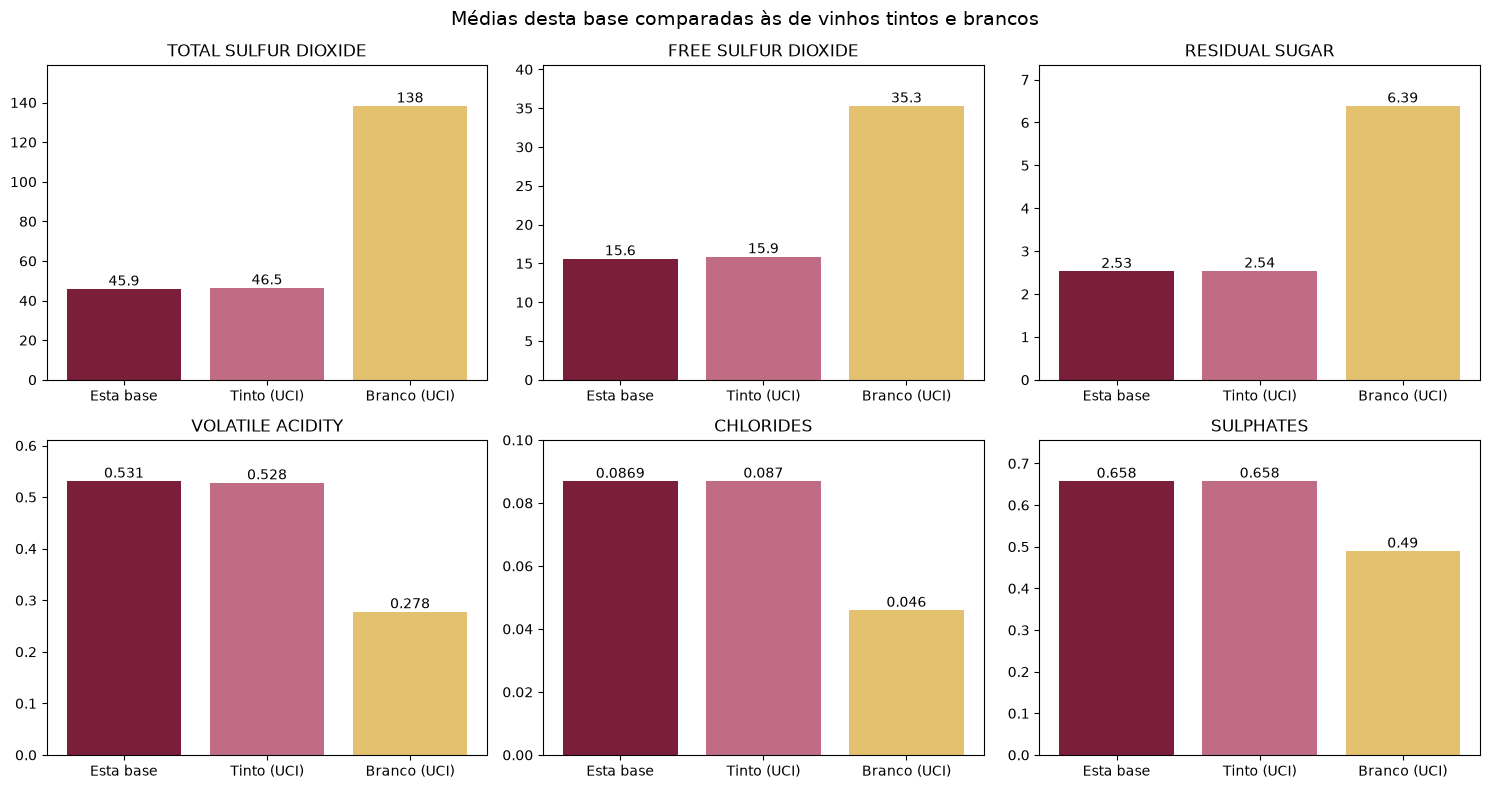

In [19]:
# Médias da base original (UCI Wine Quality, Cortez et al., 2009): 1599 tintos e 4898 brancos
referencia = pd.DataFrame({
    'Tinto (UCI)': {'total sulfur dioxide': 46.47, 'free sulfur dioxide': 15.88, 'residual sugar': 2.54,
                    'volatile acidity': 0.528, 'chlorides': 0.087, 'sulphates': 0.658},
    'Branco (UCI)': {'total sulfur dioxide': 138.36, 'free sulfur dioxide': 35.31, 'residual sugar': 6.39,
                     'volatile acidity': 0.278, 'chlorides': 0.046, 'sulphates': 0.490},
})
comparacao = pd.concat([df[referencia.index].mean().rename('Esta base'), referencia], axis=1)

cores = ['#7b1e3a', '#c06c84', '#e3c16f']

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, variavel in zip(axes.flatten(), comparacao.index):
    valores = comparacao.loc[variavel]
    ax.bar(valores.index, valores.values, color=cores)
    for i, v in enumerate(valores.values):
        ax.text(i, v, f'{v:.3g}', ha='center', va='bottom')
    ax.set_ylim(0, valores.max() * 1.15)
    ax.set_title(variavel.upper())

fig.suptitle('Médias desta base comparadas às de vinhos tintos e brancos', fontsize=14)
plt.tight_layout()
plt.show()

**CONCLUSÃO COR:**

O dióxido de enxofre total é a evidência mais clara: a média desta base (45,9 mg/L) é praticamente igual à dos tintos (46,5 mg/L) e três vezes menor que a dos brancos (138,4 mg/L). Vinhos tintos precisam de menos SO₂ porque os taninos e polifenóis da casca da uva já funcionam como antioxidantes naturais.

O mesmo padrão aparece nas outras variáveis: em relação aos brancos, esta base tem menos açúcar residual e menos SO₂ livre, e mais acidez volátil, cloretos e sulfatos — sempre com valores quase idênticos aos dos tintos.

Como todos os vinhos são tintos, a cor não pode ser usada para explicar a qualidade, e as conclusões deste trabalho valem apenas para vinhos tintos.

### Correlação entre variáveis

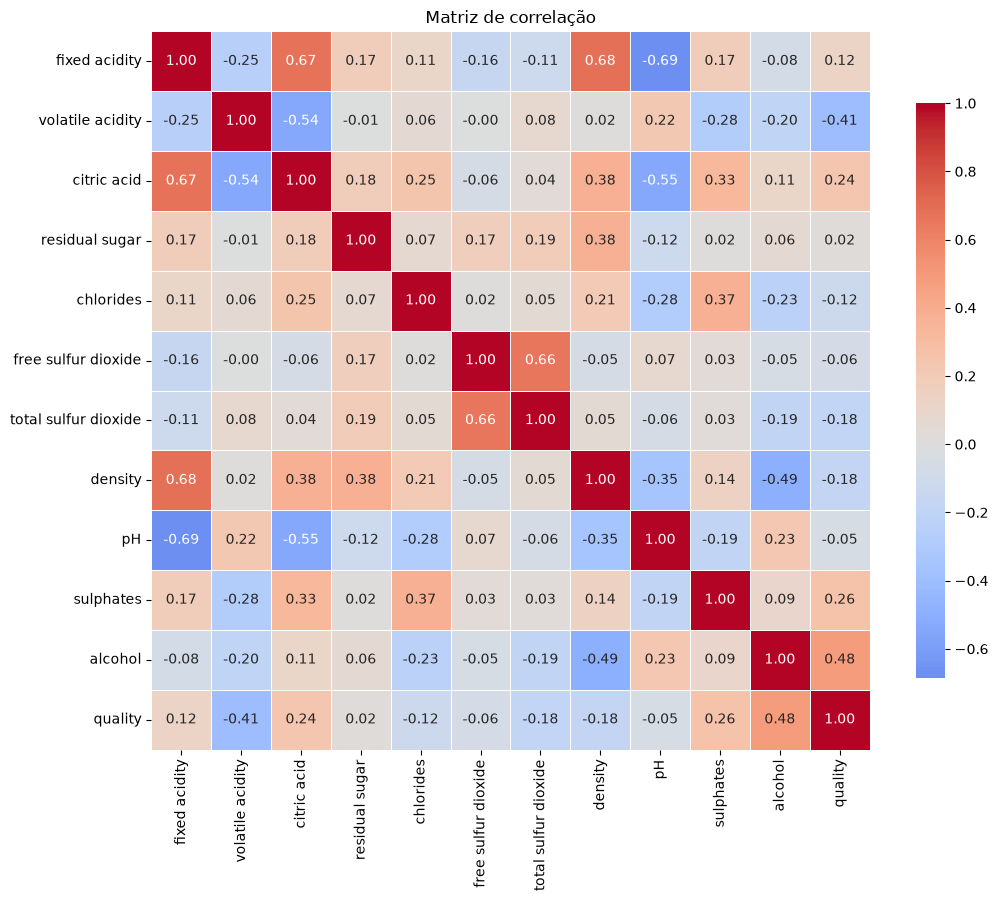

In [20]:
corr = df.drop(columns=['Id', 'alta_qualidade']).corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Matriz de correlação')
plt.tight_layout()
plt.show()

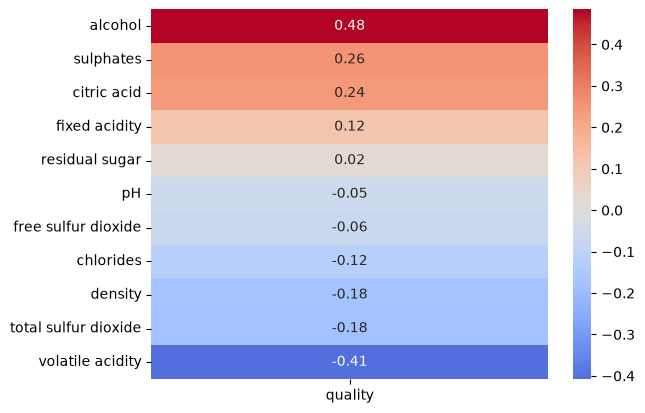

In [21]:
correlacao_qualidade = corr['quality'].drop('quality').sort_values(ascending=False)


sns.heatmap(correlacao_qualidade.to_frame(), annot=True, cmap = "coolwarm", fmt='.2f', center=0)
plt.show()

In [22]:
corr['quality'].drop('quality').sort_values(ascending=False).round(3)

alcohol                 0.485
sulphates               0.258
citric acid             0.241
fixed acidity           0.122
residual sugar          0.022
pH                     -0.052
free sulfur dioxide    -0.063
chlorides              -0.124
density                -0.175
total sulfur dioxide   -0.183
volatile acidity       -0.407
Name: quality, dtype: float64

**CONCLUSÃO CORRELAÇÃO:**

Para a correlação usamos a nota original (`quality`, de 3 a 8) em vez do alvo binário `alta_qualidade`. A versão binária junta as notas 3 a 6 numa única classe e perde informação: por exemplo, a acidez volátil cai de forma contínua da nota 3 até a 7, mas essa diferença entre vinhos ruins e medianos fica escondida no alvo binário. A `quality` mostra a relação completa entre a química e a nota. Ela é usada **apenas na análise exploratória** e não entra no modelo, já que o alvo é derivado dela (seria vazamento de dados).

As variáveis com maior correlação (em módulo) com `quality` são:

- **Alcohol (0.49)**: correlação positiva mais forte. Confirma o que já tínhamos visto nos boxplots — vinhos mais alcoólicos tendem a ser mais bem avaliados.
- **Volatile acidity (-0.41)**: correlação negativa mais forte. Excesso de acidez volátil é associado a defeitos de sabor (gosto de vinagre), então faz sentido prejudicar a nota.
- **Sulphates (0.26)** e **Citric acid (0.24)**: correlações positivas moderadas, também já indicadas nos boxplots por qualidade.
- **Total sulfur dioxide (-0.18)** e **Density (-0.18)**: correlações negativas fracas. A densidade provavelmente aparece porque está relacionada ao teor alcoólico (vinhos com mais álcool são menos densos, correlação de -0.50 entre as duas), capturando parte do mesmo efeito do alcohol.
- **Residual sugar (0.02)**: praticamente sem correlação com a qualidade, confirmando a observação anterior nos boxplots de que esse atributo não diferencia bem vinhos bons de medianos/ruins.

Nenhuma variável isoladamente tem correlação forte (>0.5) com a qualidade, o que já era esperado — a qualidade sensorial do vinho é resultado da combinação de múltiplos atributos físico-químicos, reforçando a necessidade de um modelo multivariado em vez de uma regra simples baseada em 1-2 variáveis.

Entre as próprias variáveis explicativas, as correlações mais altas são `fixed acidity` x `pH` (-0.69), `fixed acidity` x `density` (0.68), `fixed acidity` x `citric acid` (0.67) e `free sulfur dioxide` x `total sulfur dioxide` (0.66) — todas esperadas, já que acidez afeta diretamente densidade e pH do vinho, e o SO2 livre é parte do SO2 total. Não chegam a ser multicolinearidade extrema (>0.9) a ponto de exigir remoção de variáveis antes da modelagem.

## 3. Pré-processamento de Dados

**Dados faltantes:** já verificado na exploração inicial — não há valores nulos em nenhuma coluna, então não é necessário nenhum tratamento aqui.

**Feature engineering:** avaliamos a ideia de usar a categoria de doçura, vista na etapa 2, como variável do modelo, mas descartamos — a correlação do `residual sugar` com a qualidade é praticamente zero (0.02) e quase todos os vinhos caem na mesma categoria (seco: 92% pela regra brasileira e 99,5% pela europeia), então a feature não traria poder discriminativo ao modelo.

### Separação treino/teste e padronização

In [23]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['Id', 'quality', 'alta_qualidade'])
y = df['alta_qualidade']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print('Treino:', X_train.shape, '| Teste:', X_test.shape)
print('Balanceamento treino:', y_train.value_counts(normalize=True).round(3).to_dict())
print('Balanceamento teste:', y_test.value_counts(normalize=True).round(3).to_dict())

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Treino: (914, 11) | Teste: (229, 11)
Balanceamento treino: {0: 0.861, 1: 0.139}
Balanceamento teste: {0: 0.86, 1: 0.14}


O split foi feito **antes** da padronização, e o `StandardScaler` foi ajustado (`fit`) somente nos dados de treino — isso evita vazamento de informação do teste para o treino (data leakage). Usamos `stratify=y` para manter a mesma proporção de 86.1%/13.9% em treino e teste, já que o alvo é desbalanceado.

A padronização é necessária para os modelos sensíveis à escala das variáveis, como SVM, KNN e Regressão Logística, e não prejudica os demais (o Random Forest, por exemplo, é invariante a escala). Por isso usamos os mesmos dados padronizados em todos os modelos.

## 4. Desenvolvimento de Modelos

Treinamos e comparamos seis modelos de classificação: **Random Forest, SVM, Regressão Logística, Naive Bayes, KNN e Árvore de Decisão**. Os **dois melhores** seguem para a avaliação detalhada (etapa 5) e para a interpretação dos resultados (etapa 6).

Como o alvo é desbalanceado (86.1% / 13.9%), usamos `class_weight='balanced'` nos modelos que oferecem essa opção (Naive Bayes e KNN não oferecem) — isso faz o algoritmo penalizar mais os erros na classe minoritária (vinhos de alta qualidade) durante o treino, sem precisar duplicar ou gerar dados sintéticos.

### Comparação entre os modelos

Todos os modelos usam a mesma divisão treino/teste e os mesmos dados padronizados.

Como o teste tem apenas 32 vinhos de alta qualidade, o resultado de uma única divisão pode depender da sorte. Por isso, além do teste, fazemos uma **validação cruzada estratificada com 5 dobras**: a base é dividida em 5 partes, e cada modelo é treinado 5 vezes, sempre testado numa parte diferente. A média das 5 rodadas é uma estimativa mais confiável do desempenho.

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score

modelos = {
    'Random Forest': RandomForestClassifier(class_weight='balanced', n_estimators=300, random_state=42),
    'Regressão Logística': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
    'SVM': SVC(class_weight='balanced', probability=True, random_state=42),
    'Naive Bayes': GaussianNB(),
    'KNN': KNeighborsClassifier(),
    'Árvore de Decisão': DecisionTreeClassifier(class_weight='balanced', random_state=42),
}

validacao = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

linhas = []
for nome, modelo in modelos.items():
    modelo.fit(X_train_scaled, y_train)
    pred = modelo.predict(X_test_scaled)
    proba = modelo.predict_proba(X_test_scaled)[:, 1]

    # Validação cruzada com o scaler dentro do pipeline, para não vazar informação entre as dobras
    cv = cross_validate(make_pipeline(StandardScaler(), modelo), X, y, cv=validacao, scoring=['f1', 'roc_auc'])

    linhas.append({
        'Modelo': nome,
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'Acurácia': accuracy_score(y_test, pred),
        'F1 (teste)': f1_score(y_test, pred),
        'ROC-AUC (teste)': roc_auc_score(y_test, proba),
        'F1 (val. cruzada)': cv['test_f1'].mean(),
        'ROC-AUC (val. cruzada)': cv['test_roc_auc'].mean(),
    })

comparacao_modelos = pd.DataFrame(linhas).set_index('Modelo').round(3)
comparacao_modelos = comparacao_modelos.sort_values('ROC-AUC (val. cruzada)', ascending=False)
comparacao_modelos

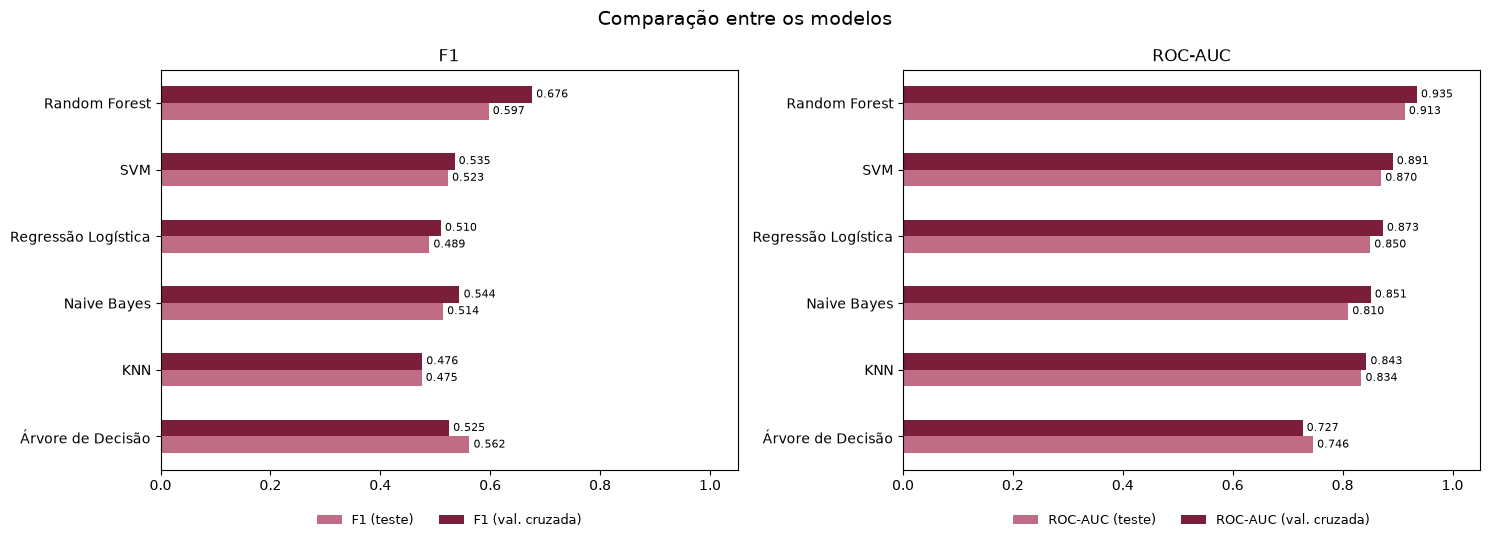

In [26]:
ordem = comparacao_modelos.sort_values('ROC-AUC (val. cruzada)').index

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

for ax, metrica in zip(axes, ['F1', 'ROC-AUC']):
    dados = comparacao_modelos.loc[ordem, [f'{metrica} (teste)', f'{metrica} (val. cruzada)']]
    dados.plot(kind='barh', color=['#c06c84', '#7b1e3a'], ax=ax)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.3f', padding=3, fontsize=8)
    ax.set_xlim(0, 1.05)
    ax.set_title(metrica)
    ax.set_ylabel('')
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=9, frameon=False)

fig.suptitle('Comparação entre os modelos', fontsize=14)
plt.tight_layout()
plt.show()

**CONCLUSÃO COMPARAÇÃO:**

- **O Random Forest é o melhor modelo:** tem a maior ROC-AUC no teste (0.913) e na validação cruzada (0.935), e o maior F1 no teste (0.597) e na validação cruzada (0.676).
- **O SVM é o segundo melhor em ROC-AUC**, no teste (0.870) e na validação cruzada (0.891), e tem o maior recall entre todos os modelos (0.719).
- **A Regressão Logística vem logo atrás do SVM** (ROC-AUC de 0.850 no teste e 0.873 na validação cruzada), seguida por **Naive Bayes** e **KNN** (0.851 e 0.843 na validação cruzada).
- **A Árvore de Decisão é a pior em ROC-AUC** (0.746 no teste e 0.727 na validação cruzada). Uma única árvore devolve probabilidades pouco graduadas (quase sempre 0 ou 1), então ordena mal os vinhos.

O critério de escolha é a **ROC-AUC na validação cruzada**, porque ela não depende do corte de 50% e é mais estável do que uma única divisão. Pelo F1 a ordem muda um pouco atrás do Random Forest: no teste, a Árvore de Decisão (0.562) fica à frente do SVM (0.523); na validação cruzada, o Naive Bayes (0.544) fica à frente (0.535). Mesmo assim, os dois ficam atrás do SVM em ROC-AUC.

**Modelos escolhidos para a avaliação detalhada: Random Forest e SVM.**

## 5. Avaliação dos Modelos

Como o alvo é desbalanceado, acurácia sozinha é enganosa (prever sempre "baixa qualidade" já daria ~86% de acerto). Por isso avaliamos **precision, recall e F1 por classe**, além do **ROC-AUC**, que são mais informativos sobre a capacidade real de identificar os vinhos de alta qualidade.

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Os dois melhores pela ROC-AUC na validação cruzada (a tabela já está ordenada por ela)
melhores = list(comparacao_modelos.index[:2])

for nome in melhores:
    pred = modelos[nome].predict(X_test_scaled)
    proba = modelos[nome].predict_proba(X_test_scaled)[:, 1]
    print(f'=== {nome} ===')
    print(classification_report(y_test, pred, digits=3, target_names=['Baixa/Média', 'Alta']))
    print('ROC AUC:', round(roc_auc_score(y_test, proba), 3))
    print()

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, nome in zip(axes, melhores):
    cm = confusion_matrix(y_test, modelos[nome].predict(X_test_scaled))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Reds', cbar=False,
                xticklabels=['Baixa/Média', 'Alta'], yticklabels=['Baixa/Média', 'Alta'], ax=ax)
    ax.set_title(nome)
    ax.set_xlabel('Predito')
    ax.set_ylabel('Real')

plt.tight_layout()
plt.show()

**CONCLUSÃO AVALIAÇÃO:**

| Métrica (classe Alta) | Random Forest | SVM |
|---|---|---|
| Precision | 0.571 | 0.411 |
| Recall | 0.625 | 0.719 |
| F1-score | 0.597 | 0.523 |
| Acurácia geral | 0.882 | 0.817 |
| ROC-AUC | 0.913 | 0.870 |

O **Random Forest** supera o SVM em precision, F1, acurácia e ROC-AUC, e erra bem menos no total: 27 erros (15 falsos positivos e 12 falsos negativos), contra 42 do SVM (33 falsos positivos e 9 falsos negativos).

O **SVM** tem o recall mais alto (0.719 vs 0.625) — ou seja, ele "captura" mais vinhos realmente bons: 23 dos 32 do teste, contra 20 do Random Forest. O custo é uma precisão bem menor (0.411): dos 56 vinhos que ele classifica como "alta qualidade", 33 na verdade não são. Isso pode ser útil se o objetivo de negócio for **perder o mínimo de vinhos bons** (ex: triagem inicial, onde falsos positivos custam pouco), mas para decisões mais custosas (ex: investimento extra em um lote) o Random Forest é mais confiável, pois erra menos no total.

Dado o desempenho superior e mais equilibrado, adotamos o **Random Forest como modelo principal**, com o **SVM como alternativa** para quando a prioridade for não deixar passar vinhos bons.

## 6. Interpretação dos Resultados

In [ ]:
importancias = pd.Series(modelos['Random Forest'].feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 6))
plt.barh(importancias.index, importancias.values, color='#7b1e3a')
plt.title('Importância das variáveis (Random Forest)')
plt.xlabel('Importância')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.inspection import permutation_importance

permutacao = pd.DataFrame({
    nome: permutation_importance(modelos[nome], X_test_scaled, y_test, scoring='roc_auc',
                                 n_repeats=30, random_state=42).importances_mean
    for nome in melhores
}, index=X.columns)

ordem_permutacao = permutacao.mean(axis=1).sort_values().index

permutacao.loc[ordem_permutacao].plot(kind='barh', color=['#7b1e3a', '#c06c84'], figsize=(9, 6))
plt.title('Importância por permutação nos dois melhores modelos')
plt.xlabel('Queda na ROC-AUC ao embaralhar a variável')
plt.tight_layout()
plt.show()

**Importância por permutação.** O SVM não tem uma medida interna de importância como o Random Forest. Para comparar os dois modelos pelo mesmo critério, usamos a importância por permutação: embaralhamos os valores de uma variável no conjunto de teste e medimos quanto a ROC-AUC cai. Quanto maior a queda, mais o modelo depende daquela variável.

- **Os dois modelos concordam nas 4 variáveis mais importantes:** alcohol é a principal nos dois (queda de 0.073 no Random Forest e 0.086 no SVM), seguida por sulphates, total sulfur dioxide e volatile acidity.
- **Citric acid perde força:** cai para 0.019 no Random Forest e 0.003 no SVM, embora apareça em 2º lugar na importância interna do Random Forest. Uma explicação provável é a correlação com outras variáveis: ela tem correlação de 0.67 com a fixed acidity, então parte da sua informação também está em outros atributos.
- **Residual sugar e pH têm importância praticamente nula** nos dois modelos, o que confirma a EDA.

Esses valores são uma estimativa com pouca precisão, porque o teste tem apenas 32 vinhos de alta qualidade. A ordem exata entre variáveis próximas não deve ser levada ao pé da letra.

**CONCLUSÃO FINAL:**

Entre os seis modelos comparados, os dois melhores foram o **Random Forest** (modelo principal) e o **SVM** (alternativa com maior recall).

As variáveis de maior influência na previsão de qualidade são:

1. **Alcohol** — a mais importante nos dois modelos e nas duas medidas de importância (0.22 na importância interna do Random Forest), consistente com a correlação (0.49) e os boxplots vistos na EDA.
2. **Sulphates** e **Volatile acidity** — relevantes nos dois modelos e já destacadas na EDA e na matriz de correlação.
3. **Total sulfur dioxide** — tem peso na permutação dos dois modelos, embora sua importância interna no Random Forest seja baixa (0.07).
4. **Citric acid** — o resultado varia conforme a medida: é a 2ª na importância interna do Random Forest (0.14), mas fica bem abaixo na permutação, principalmente no SVM. É um sinal menos consistente.

O `residual sugar` e o `pH`, que já havíamos identificado como pouco relevantes, confirmam-se como as variáveis de menor peso nos dois modelos.

**Implicações para o processo de produção:**

- **Teor alcoólico** é o fator dominante — processos de fermentação que resultem em maior teor alcoólico (dentro dos limites estilísticos do vinho) tendem a favorecer notas mais altas. Vale priorizar controle de fermentação (temperatura, leveduras, tempo) como alavanca de qualidade.
- **Acidez volátil baixa** está associada a vinhos melhores — isso reforça a importância de controle sanitário e de oxidação durante a vinificação, já que acidez volátil alta normalmente indica contaminação bacteriana (ex: bactérias acéticas) ou manejo inadequado.
- **Sulfatos**, usados como conservantes/estabilizantes, parecem contribuir positivamente — sugerindo que a dosagem correta é relevante para a qualidade final, não apenas para conservação.
- **Dióxido de enxofre total** tende a ser menor nos vinhos de alta qualidade (correlação de -0.18), então vale acompanhar a dosagem desse conservante.
- **Ácido cítrico** é mais alto nos vinhos bons, mas seu peso varia entre os modelos, então é uma pista a investigar, não uma alavanca confirmada.
- Variáveis como **açúcar residual e pH têm baixo impacto nos modelos**, indicando que ajustes finos nesses pontos tendem a gerar menos retorno em termos de qualidade percebida, comparado a investir em controle de álcool e acidez volátil.

**Uso recomendado:** o Random Forest para decisões em que errar custa caro, por errar menos no total, e o SVM como triagem, quando a prioridade for não deixar passar vinhos bons.

É importante frisar que essas são **correlações/importâncias estatísticas, não relações causais comprovadas** — a recomendação para produtores é usar os modelos como apoio à decisão (ex: priorizar lotes para análise sensorial humana), e não como substituto definitivo da avaliação de especialistas.